<br> <CENTER> **Decision Tree** </br>

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.model_selection import train_test_split

%matplotlib inline

In [3]:
data='https://raw.githubusercontent.com/gastonstat/CreditScoring/refs/heads/master/CreditScoring.csv'

!curl $data -o creditscoring.csv

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100 178.2k 100 178.2k   0      0 341.4k      0                              0
100 178.2k 100 178.2k   0      0 341.2k      0                              0
100 178.2k 100 178.2k   0      0 340.9k      0                              0


In [4]:
df=pd.read_csv('creditscoring.csv')

In [5]:
df

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4450,2,1,1,60,39,2,1,1,69,92,0,0,900,1020
4451,1,22,2,60,46,2,1,1,60,75,3000,600,950,1263
4452,2,0,2,24,37,2,1,2,60,90,3500,0,500,963
4453,1,0,1,48,23,1,1,3,49,140,0,0,550,550


Data Cleaning and prepration

In [6]:
df.columns=df.columns.str.lower().str.replace(' ', '_')

In [7]:
df

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4450,2,1,1,60,39,2,1,1,69,92,0,0,900,1020
4451,1,22,2,60,46,2,1,1,60,75,3000,600,950,1263
4452,2,0,2,24,37,2,1,2,60,90,3500,0,500,963
4453,1,0,1,48,23,1,1,3,49,140,0,0,550,550


In [8]:
status_values={
    1: 'good',
    2: 'bad',
    0: 'unk'
}

df['status']=df['status'].map(status_values)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}
df['home']=df['home'].map(home_values)


marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}
df['marital']=df['marital'].map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df['records']=df['records'].map(records_values)


job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}
df['job']=df['job'].map(job_values)

In [9]:
for c in ['income', 'assets', 'debt']:
    df[c]=df[c].replace(to_replace=99999999.0, value=np.nan)

In [10]:
df=df[df['status']!='unk'].reset_index(drop=True)

In [11]:
df_full_train, df_test=train_test_split(df,test_size=0.2,
    random_state=11)

df_train,df_val= train_test_split(df_full_train,test_size=0.25,
    random_state=11
)

In [12]:
df_full_train=df_full_train.reset_index(drop=True)
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [13]:
df_full_train['status']=(df_full_train.status=='bad').astype('int')
df_train['status']=(df_train.status=='bad').astype('int')
df_val['status']=(df_val.status=='bad').astype('int')
df_test['status']=(df_test.status=='bad').astype('int')

In [14]:
y_full_train=df_full_train.status.values
y_train=df_train.status.values
y_val=df_val.status.values
y_test=df_test.status.values

In [15]:
del df_full_train['status']
del df_train['status']
del df_val['status']
del df_test['status']

<br> <center> Decision Tree </br>

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer

from sklearn.metrics import roc_auc_score

In [17]:
def assess_risk(xi):
    
    if xi['records']=='yes':
        if xi['job']=='partime':
            return 'bad'
        else:
            return 'good'
    else:
        if xi['assets']> 6000:
            return 'good'
        else:
            return 'bad'

In [18]:
train_dicts= df_train.to_dict(orient="records")

dv=DictVectorizer(sparse=False)
x_train=dv.fit_transform(train_dicts)


In [19]:
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [20]:
val_dicts= df_val.to_dict(orient="records")
x_val=dv.transform(val_dicts)

y_pred=dt.predict_proba(x_val)[:,1]

In [21]:
y_pred

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 1., 1., 0., 0., 1., 0.,
       1., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 0.,
       0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
       1., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0.,
       0., 1., 1., 1., 0., 1., 0., 0., 0., 0., 0., 1., 1., 0., 0., 1., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1., 1., 0., 1., 0., 0., 0.,
       1., 0., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 1., 1., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 1., 1., 0., 1., 0., 0.,
       0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0.,
       0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 1., 0.,
       1., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 1., 0., 0.

In [22]:
roc_auc_score(y_pred, y_val)

0.6676063523625138

In [23]:
y_pred_train=dt.predict_proba(x_train)[:,1]
roc_auc_score(y_train, y_pred_train)

1.0

In [24]:
dt=DecisionTreeClassifier(max_depth=3)
dt.fit(x_train,y_train)

y_pred=dt.predict_proba(x_train)[:,1]

auc=roc_auc_score(y_train,y_pred)
print('train', auc)

y_pred=dt.predict_proba(x_val)[:,1]

auc=roc_auc_score(y_val, y_pred)
print('val', auc)

train 0.7761016984958594
val 0.7389079944782155


In [25]:
from sklearn.tree import export_text
print(export_text(dt, feature_names=dv.get_feature_names_out()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- class: 1
|   |   |--- income >  103.50
|   |   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- class: 0
|   |   |--- income >  74.50
|   |   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- assets <= 8750.00
|   |   |   |--- class: 1
|   |   |--- assets >  8750.00
|   |   |   |--- class: 0



In [ ]:
# df_example= pd.DataFrame({
#     "owns_home":  ["yes", "no", "yes", "no", "yes", "no", "no", "yes", "no", "yes"],
#     "employment": ["salaried", "salaried", "self", "unemployed", "salaried", "self", "unemployed", "self", "salaried", "unemployed"],
#     "education":  ["college", "hs", "grad", "hs", "grad", "college", "college", "hs", "college", "college"],
#     "age":        [34, 25, 45, 52, 29, 38, 23, 41, 31, 60],
#     "income":     [72, 41, 95, 18, 66, 54, 22, 47, 58, 30],
#     "approved":   ["yes", "no", "yes", "no", "yes", "yes", "no", "no", "yes", "no"],
# })
# df_example

,owns_home,employment,education,age,income,approved
0,yes,salaried,college,34,72,yes
1,no,salaried,hs,25,41,no
2,yes,self,grad,45,95,yes
3,no,unemployed,hs,52,18,no
4,yes,salaried,grad,29,66,yes
5,no,self,college,38,54,yes
6,no,unemployed,college,23,22,no
7,yes,self,hs,41,47,no
8,no,salaried,college,31,58,yes
9,yes,unemployed,college,60,30,no


In [ ]:
# def gini_age(df, target="approved"):
#     n = len(df)
#     best_gini = 1
#     best_threshold = None

#     for t in sorted(df["income"].unique())[:-1]:
#         left = df[df["income"] <= t]
#         right = df[df["income"] > t]

#         weighted = len(left) / n * gini(left[target]) + len(right) / n * gini(right[target])

#         if weighted < best_gini:
#             best_gini = weighted
#             best_threshold = t

#     return best_gini, best_threshold

# gini_age(df_example)
    

(np.float64(0.0), np.int64(47))

In [ ]:
# def gini(labels):
    
#     proprtion=labels.value_counts(normalize=True)
    
#     return 1 - (proprtion**2).sum()

In [ ]:
# weighted_gini=0
# for val, groups in df_example.groupby('job'):
    
#     print(groups)
#     print(groups['status'])
#     weighted_gini += (len(groups['status']) / len(df_example.records))  *  gini(groups['status'])
#     print(weighted_gini.round(3))
    

In [ ]:
# def gini_records(df, var, target="status"):
#     n = len(df)
#     weighted = 0
#     for value, group in df.groupby(var):
#         weighted += len(group) / n * gini(group[target])
#     return weighted

# gini_records(df_example)

np.float64(0.3999999999999999)

In [ ]:
# records=.40
# jobs=.271

In [ ]:
# dics_d={}
# for val in sorted(df_example.age.unique())[:-1]:
    
#     df_left=df_example[df_example.age <= val]
#     df_right=df_example[df_example.age>val ]
    
#     print(val)
#     display(df_left)
#     print(df_left['status'].value_counts(normalize=True))
#     display(df_right)
#     print(df_right['status'].value_counts(normalize=True))
    
    
    
    

In [ ]:

# def gini_age(df, target="status"):
#     n = len(df)
#     best_gini = 1
#     best_threshold = None

#     for t in sorted(df["age"].unique())[:-1]:
#         left = df[df["age"] <= t]
#         right = df[df["age"] > t]

#         weighted = len(left) / n * gini(left[target]) + len(right) / n * gini(right[target])

#         if weighted < best_gini:
#             best_gini = weighted
#             best_threshold = t

#     return best_gini, best_threshold

# gini_age(df_example)

(np.float64(0.3), np.int64(45))

Parameter Tuning

In [26]:
par_d={}

for d in [2,3,4,5,6,7,8,9,10]:
    
    dt=DecisionTreeClassifier(max_depth=d)
    
    dt.fit(x_train,y_train)
    
    y_pred=dt.predict_proba(x_val)[:,1]
    auc=roc_auc_score(y_val, y_pred)
    par_d[d]=auc
    

In [27]:
par_d

{2: 0.6685264343319367,
 3: 0.7389079944782155,
 4: 0.7607257029376862,
 5: 0.7664291249909181,
 6: 0.7618730473953161,
 7: 0.7338584679470103,
 8: 0.7316727616187547,
 9: 0.70196895207188,
 10: 0.6847224576784288}

In [28]:
scores=[]
for d in [4,5]:
    
    for s in [2, 4, 8, 16, 32, 40 , 80, 150 , 300, 500]:
        
        dt=DecisionTreeClassifier(max_depth=d, max_leaf_nodes=s)
        dt.fit(x_train,y_train)

        y_pred=dt.predict_proba(x_val)[:,1]
        auc=roc_auc_score(y_val, y_pred)
        scores.append((d,s,auc))
        


In [29]:
df_scores=pd.DataFrame(scores,columns=['max_depth', 'max_leaf_node', 'auc'])
df_scores

,max_depth,max_leaf_node,auc
0,4,2,0.605864
1,4,4,0.717021
2,4,8,0.752806
3,4,16,0.760726
4,4,32,0.760726
5,4,40,0.760726
6,4,80,0.760726
7,4,150,0.760726
8,4,300,0.760726
9,4,500,0.760726


In [30]:
df_scores.sort_values(by=['auc','max_leaf_node'], ascending=[False,True])

,max_depth,max_leaf_node,auc
14,5,32,0.766429
15,5,40,0.766429
16,5,80,0.766429
17,5,150,0.766429
18,5,300,0.766429
19,5,500,0.766429
13,5,16,0.760765
3,4,16,0.760726
4,4,32,0.760726
5,4,40,0.760726


<Axes: xlabel='max_depth', ylabel='max_leaf_node'>

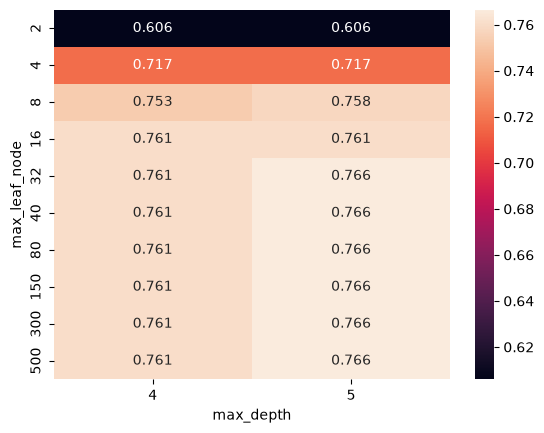

In [31]:
grid = df_scores.groupby(["max_leaf_node", "max_depth"])["auc"].mean().unstack()

sns.heatmap(grid, annot=True, fmt=".3f")

In [32]:
dt=DecisionTreeClassifier(max_depth=5, min_samples_leaf=32)
dt.fit(x_train,y_train)

test_dicts=df_test.to_dict(orient="records")
x_test=dv.transform(test_dicts)

In [33]:
auc

0.7664291249909181

Ensembles and  Random Forest 

In [34]:
from sklearn.ensemble import RandomForestClassifier

In [35]:
rf=RandomForestClassifier(n_estimators=10, random_state=62)
rf.fit(x_train,y_train)

y_pred=rf.predict_proba(x_val)[:,1]
auc=roc_auc_score(y_val,y_pred)
auc

0.7858492165362911

In [ ]:
scores=[]

for d in [1,2,4,5,6,10,15, 30, 50 ]:
    for n in [1,5,10,20,40,50]:
        rf=RandomForestClassifier(n_estimators=90,random_state=62, max_depth=d, min_samples_leaf=n)
        rf.fit(x_train,y_train)

        y_pred=rf.predict_proba(x_val)[:,1]
        auc=roc_auc_score(y_val,y_pred)
        scores.append((d, n,auc))
    

In [37]:
df_scores=pd.DataFrame(scores,columns=['depth', 'numer_of_leafs' ,'auc'])
df_scores.sort_values(['auc','numer_of_leafs'] ,ascending=(False, True))

,depth,numer_of_leafs,auc
36,15,1,0.826424
32,10,10,0.826024
30,10,1,0.824384
31,10,5,0.823899
44,30,10,0.821417
50,50,10,0.821417
43,30,5,0.820975
49,50,5,0.820975
37,15,5,0.820164
38,15,10,0.820145


Gradient Boosting and XGBoost

In [38]:
import xgboost as xgb

In [39]:
features=dv.feature_names_
dtrain=xgb.DMatrix(data=x_train,label=y_train, feature_names=features)
d_val=xgb.DMatrix(data=x_val,label=y_val, feature_names=features)

In [40]:
xgb_params={
    'learning_rate': 0.3,
    'max_depth': 6,
    'min_child_weight':1,
    
    'verbosity':1,
    
    'booster':'gbtree',
    'seed':1,
    'nthread':8
    
}
model=xgb.train(xgb_params, dtrain , num_boost_round=10)

In [41]:
y_pred=model.predict(d_val)

In [42]:
roc_auc_score(y_val,y_pred)

0.8153078152624058

In [43]:
watchlist=[(dtrain,'train'), (d_val, 'val')]

In [146]:
%%capture output

xgb_params={
    'learning_rate': 0.05,
    'max_depth': 6,
    'min_child_weight':1,
    
    'verbosity':1,
    
    'booster':'gbtree',
    'seed':1,
    'nthread':8,
    'eval_metric': 'auc'
    
}
model=xgb.train(xgb_params, dtrain , num_boost_round=200, evals=watchlist, verbose_eval=1)

In [45]:
results=[]

for a in output.stdout.strip().split('\n'):
    # print(a)
    iter, training_auc, validation_auc=a.split('\t')
    xg_iter=(int(iter.strip('[]')))
    xg_train_auc=(float(training_auc.split(':')[1]))
    xg_val_auc=(float(validation_auc.split(':')[1]))
    
    results.append((xg_iter,xg_train_auc,xg_val_auc))

In [46]:
df_scores=pd.DataFrame(results, columns=['iterations','training_auc', 
                                         'validation_auc'])
df_scores


,iterations,training_auc,validation_auc
0,0,0.87677,0.77999
1,1,0.89035,0.79899
2,2,0.91100,0.80280
3,3,0.92013,0.80746
4,4,0.92963,0.80728
...,...,...,...
195,195,1.00000,0.80790
196,196,1.00000,0.80784
197,197,1.00000,0.80800
198,198,1.00000,0.80802


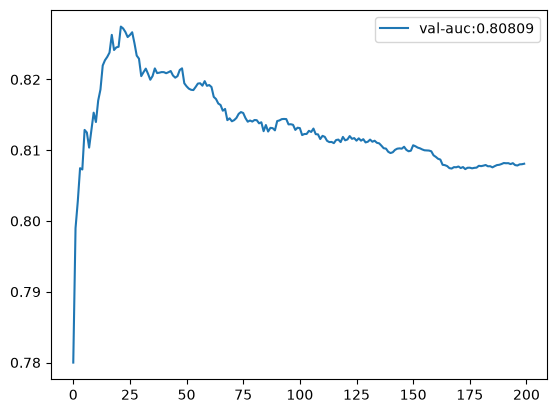

In [47]:
# plt.plot(df_scores.iterations,df_scores.training_auc, label=training_auc)
plt.plot(df_scores.iterations,df_scores.validation_auc, label=validation_auc)
plt.legend()

In [139]:
from IPython.utils.capture import capture_output
eta_rate=[0.1, 0.03, 0.05]
scores={}
for e in eta_rate:
    xgb_params['learning_rate']=e
    with capture_output() as output:
        xgb.train(xgb_params, dtrain, num_boost_round=200 , evals=watchlist, verbose_eval=1)
    results=[]
    for a in output.stdout.strip().split('\n'):
        
        # print(a)
        it, training_auc, validation_auc=a.split('\t')
        xg_iter=(int(it.strip('[]')))
        xg_train_auc=(float(training_auc.split(':')[1]))
        xg_val_auc=(float(validation_auc.split(':')[1]))

        results.append((xg_iter,xg_train_auc,xg_val_auc))
    
    scores['learning_rate:%s' % e]= pd.DataFrame(results, columns=['it', 'training_auc', 'validation_auc'])
    

In [140]:
scores

{'learning_rate:0.1':       it  training_auc  validation_auc
 0      0       0.87677         0.77999
 1      1       0.88233         0.77843
 2      2       0.88586         0.78300
 3      3       0.89328         0.79351
 4      4       0.89764         0.80026
 ..   ...           ...             ...
 195  195       0.99963         0.81115
 196  196       0.99964         0.81106
 197  197       0.99966         0.81134
 198  198       0.99970         0.81127
 199  199       0.99970         0.81103
 
 [200 rows x 3 columns],
 'learning_rate:0.03':       it  training_auc  validation_auc
 0      0       0.87677         0.77999
 1      1       0.87926         0.78025
 2      2       0.88091         0.78118
 3      3       0.88271         0.78114
 4      4       0.88311         0.78005
 ..   ...           ...             ...
 195  195       0.98212         0.82787
 196  196       0.98220         0.82793
 197  197       0.98223         0.82797
 198  198       0.98247         0.82791
 199  199 

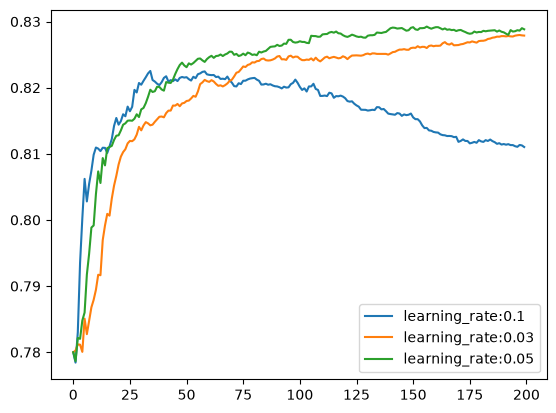

In [141]:
for key,p in scores.items():
    plt.plot(scores[key].it, scores[key].validation_auc, label=key)
    plt.legend()
    

In [147]:
max_depth=[3,4,6,10]
scores={}
for e in max_depth:
    xgb_params['max_depth']=e
    with capture_output() as output:
        xgb.train(xgb_params, dtrain, num_boost_round=200 , evals=watchlist, verbose_eval=1)
    results=[]
    for a in output.stdout.strip().split('\n'):
        
        # print(a)
        it, training_auc, validation_auc=a.split('\t')
        xg_iter=(int(it.strip('[]')))
        xg_train_auc=(float(training_auc.split(':')[1]))
        xg_val_auc=(float(validation_auc.split(':')[1]))

        results.append((xg_iter,xg_train_auc,xg_val_auc))
    
    scores['max_depth:%s' % e]= pd.DataFrame(results, columns=['it', 'training_auc', 'validation_auc'])

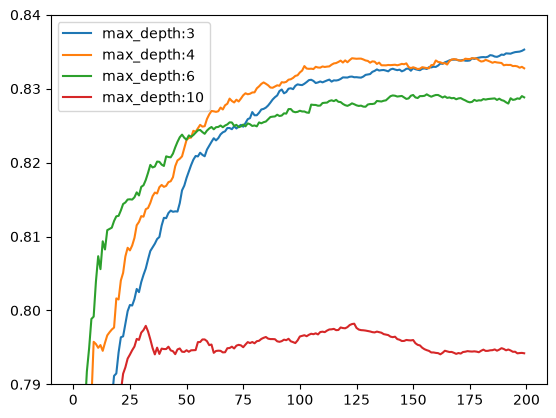

In [148]:
for key,p in scores.items():
    plt.plot(scores[key].it, scores[key].validation_auc, label=key)

plt.ylim(.79, .84)    
plt.legend()

{'learning_rate': 0.05,
 'max_depth': 10,
 'min_child_weight': 1,
 'verbosity': 1,
 'booster': 'gbtree',
 'seed': 1,
 'nthread': 8,
 'eval_metric': 'auc'}

In [160]:
child_weight=[1,5]
scores={}
xgb_params={'learning_rate': 0.05,
 'max_depth': 4,
 'min_child_weight': 1,
 'verbosity': 1,
 'booster': 'gbtree',
 'seed': 1,
 'nthread': 8,
 'eval_metric': 'auc'}
for e in child_weight:
    xgb_params['min_child_weight']=e
    with capture_output() as output:
        xgb.train(xgb_params, dtrain, num_boost_round=175 , evals=watchlist, verbose_eval=1)
    results=[]
    for a in output.stdout.strip().split('\n'):
        
        # print(a)
        it, training_auc, validation_auc=a.split('\t')
        xg_iter=(int(it.strip('[]')))
        xg_train_auc=(float(training_auc.split(':')[1]))
        xg_val_auc=(float(validation_auc.split(':')[1]))

        results.append((xg_iter,xg_train_auc,xg_val_auc))
    
    scores['min_child_weight:%s' % e]= pd.DataFrame(results, columns=['it', 'training_auc', 'validation_auc'])

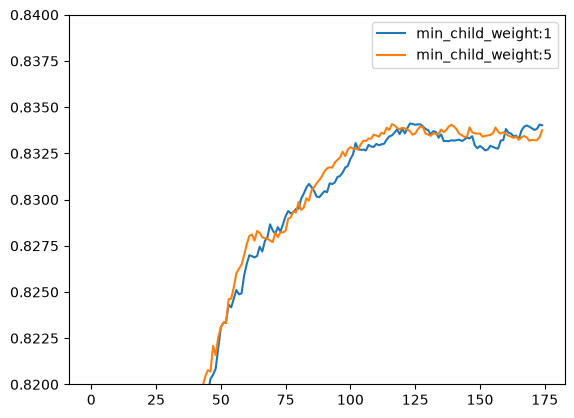

In [161]:
for key,p in scores.items():
    plt.plot(scores[key].it, scores[key].validation_auc, label=key)

plt.ylim(.82, .84)    
plt.legend()

In [ ]:
xgb_params={'learning_rate': 0.05,
 'max_depth': 4,
 'min_child_weight': 5,
 'verbosity': 1,
 'booster': 'gbtree',
 'seed': 1,
 'nthread': 8,
 'eval_metric': 'auc'}

model=xgb.train(xgb_params, dtrain, num_boost_round=175 , verbose_eval=1)

Selecting the Best Model

In [162]:
dt=DecisionTreeClassifier(max_depth=5, min_samples_leaf=32)
dt.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",32
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [169]:
y_pred=dt.predict_proba(x_val)[:,1]
roc_auc_score(y_val,y_pred)

0.7654119541788766

In [167]:
rf=RandomForestClassifier(n_estimators=90,random_state=62, max_depth=15, min_samples_leaf=1)
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",90
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",62
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [170]:
y_pred=rf.predict_proba(x_val)[:,1]
roc_auc_score(y_val,y_pred)

0.8264240391368579

In [168]:
gb_params={'learning_rate': 0.05,
 'max_depth': 4,
 'min_child_weight': 5,
 'verbosity': 1,
 'booster': 'gbtree',
 'seed': 1,
 'nthread': 8,
 'eval_metric': 'auc'}

model=xgb.train(xgb_params, dtrain, num_boost_round=175 , verbose_eval=1)

In [171]:
y_pred=model.predict(d_val)
roc_auc_score(y_val,y_pred)

0.8337500908188225

In [189]:
x_full_dicts=df_full_train.to_dict(orient="records")
dv=DictVectorizer(sparse=False)
x_full_train=dv.fit_transform(x_full_dicts)
features=dv.feature_names_

d_full_train=xgb.DMatrix(data=x_full_train, label=y_full_train, feature_names=features)

model=xgb.train(xgb_params, d_full_train, num_boost_round=175, verbose_eval=1)

x_test_dicts=df_test.to_dict(orient="records")
x_test=dv.transform(x_test_dicts)
d_test=xgb.DMatrix(data=x_test, feature_names=features)


# xgb.DMatrix(data=x_test, label=y_test, dv.feature_names_)


In [190]:
y_pred=model.predict(d_test)
roc_auc_score(y_test,y_pred)

0.8279287424857046